# Singapore HDB Resale：截至 2025 年的数据探索与预处理

本 notebook 对应 `docs/Assignment Procedure.pdf` 的数据治理、profiling、清洗与 EDA 阶段，预测目标为 **`resale_price`（SGD）**。本次先完成用户指定的初步分析；地址编码和基础模型比较留待下一阶段。

分析问题：面积、房型、楼层、剩余租期和登记时间与价格有什么关联？哪些极端记录只是少见，哪些存在字段之间的一致性问题？

数据来源：[HDB / data.gov.sg](https://data.gov.sg/datasets/d_8b84c4ee58e3cfc0ece0d773c8ca6abc/view)，下载方法：[官方 Download API](https://guide.data.gov.sg/developer-guide/dataset-apis/download-dataset)。数据从 2017 年 1 月起，动态更新；本次仅使用 **2017-01 至 2025-12** 的快照。这个快照来自当前数据源，并非保证与 2025 年底当时发布的版本完全相同。

官方说明：月份依据转售**登记日期**；面积可能包含购买的凹入空间、升级增加的空间、屋顶露台等；数据排除了可能不能反映完整市场价格的亲属间交易、部分产权交易。因此本分析描述的是该数据源中的登记交易，并不代表所有房屋或全部交易。

**AI 使用声明：** 使用 OpenAI Codex 辅助生成代码、分析方案和文字。验证方式为完整运行 notebook，检查日期边界、编码结果、数据质量表和可视化，并对发现的租期异常查看同地址记录。小组仍需亲自复核、理解并解释全部分析及结论；成员贡献应在最终提交前补充。

## 1. 环境与数据快照

在项目根目录运行 `uv sync --locked`，再运行 `uv run jupyter lab`，选择本项目 `.venv` 的 Python 3.11 内核。

默认读取本地快照，避免动态源改变本次演示结果。需要重新获取官方数据时，改为 `REFRESH_DATA = True`；刷新会覆盖快照和元数据，不会追加重复记录。元数据记录来源、获取时间、截取范围及 SHA-256。再次运行前恢复 `False`。

In [1]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import io
import json
import time

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 15)
pd.set_option("display.max_rows", 40)
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

DATASET_ID = "d_8b84c4ee58e3cfc0ece0d773c8ca6abc"
SOURCE_URL = f"https://data.gov.sg/datasets/{DATASET_ID}/view"
CUTOFF = "2025-12"
REFRESH_DATA = False
SNAPSHOT = Path("data/raw/hdb_resale_2017_2025.csv")
METADATA = SNAPSHOT.with_suffix(".metadata.json")
OUTPUT = Path("data/processed")
OUTPUT.mkdir(parents=True, exist_ok=True)

In [2]:
if REFRESH_DATA or not SNAPSHOT.exists():
    api = f"https://api-open.data.gov.sg/v1/public/api/datasets/{DATASET_ID}"
    response = requests.get(f"{api}/initiate-download", timeout=60)
    response.raise_for_status()
    download = requests.get(f"{api}/poll-download", timeout=60).json()["data"]
    while not download.get("url"):
        time.sleep(15)
        download = requests.get(f"{api}/poll-download", timeout=60).json()["data"]

    response = requests.get(download["url"], timeout=120)
    response.raise_for_status()
    source = pd.read_csv(io.BytesIO(response.content), dtype="string")
    source_month = pd.to_datetime(source["month"], format="%Y-%m")
    snapshot = source.loc[source_month.between("2017-01-01", "2025-12-31")].copy()
    SNAPSHOT.parent.mkdir(parents=True, exist_ok=True)
    snapshot.to_csv(SNAPSHOT, index=False)
    metadata = {
        "dataset_id": DATASET_ID,
        "source_url": SOURCE_URL,
        "retrieved_at": datetime.now(ZoneInfo("Asia/Shanghai")).isoformat(),
        "cutoff_month": CUTOFF,
        "source_rows": len(source),
        "source_latest_month": source["month"].max(),
        "snapshot_rows": len(snapshot),
        "snapshot_first_month": snapshot["month"].min(),
        "snapshot_last_month": snapshot["month"].max(),
        "snapshot_sha256": hashlib.sha256(SNAPSHOT.read_bytes()).hexdigest(),
    }
    METADATA.write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")

metadata = json.loads(METADATA.read_text(encoding="utf-8"))
assert hashlib.sha256(SNAPSHOT.read_bytes()).hexdigest() == metadata["snapshot_sha256"]
display(pd.Series(metadata, name="Snapshot metadata").to_frame())

,Snapshot metadata
dataset_id,d_8b84c4ee58e3cfc0ece0d773c8ca6abc
source_url,https://data.gov.sg/datasets/d_8b84c4ee58e3cfc...
retrieved_at,2026-10-11T21:23:29.895039+08:00
cutoff_month,2025-12
source_rows,242454
source_latest_month,2026-10
snapshot_rows,222066
snapshot_first_month,2017-01
snapshot_last_month,2025-12
snapshot_sha256,af2ed6574d542771426bf2236c122470d64fe9841ba8bd...


## 2. pandas 原生数据概览

先查看 `head()`、`info()`、`dtypes`、`describe()`。`block` 包含 `273A` 等值，是地址标识而不是连续数值，明确读成字符串；其余先使用 pandas 原生推断。`lease_commence_date` 虽然推断为整数，其含义是租约开始年份。

In [3]:
raw = pd.read_csv(SNAPSHOT, dtype={"block": "string"})
display(raw.head())
raw.info()
display(raw.dtypes.rename("Inferred dtype").to_frame())
display(raw.describe())
display(raw.describe(include=["object", "string"]))

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
0,2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44.000,Improved,1979,61 years 04 months,232000.000
1,2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67.000,New Generation,1978,60 years 07 months,250000.000
2,2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67.000,New Generation,1980,62 years 05 months,262000.000
3,2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68.000,New Generation,1980,62 years 01 month,265000.000
4,2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67.000,New Generation,1980,62 years 05 months,265000.000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 222066 entries, 0 to 222065
Data columns (total 11 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   month                222066 non-null  object 
 1   town                 222066 non-null  object 
 2   flat_type            222066 non-null  object 
 3   block                222066 non-null  string 
 4   street_name          222066 non-null  object 
 5   storey_range         222066 non-null  object 
 6   floor_area_sqm       222066 non-null  float64
 7   flat_model           222066 non-null  object 
 8   lease_commence_date  222066 non-null  int64  
 9   remaining_lease      222066 non-null  object 
 10  resale_price         222066 non-null  float64
dtypes: float64(2), int64(1), object(7), string(1)
memory usage: 18.6+ MB


,Inferred dtype
month,object
town,object
flat_type,object
block,string[python]
street_name,object
storey_range,object
floor_area_sqm,float64
flat_model,object
lease_commence_date,int64
remaining_lease,object


,floor_area_sqm,lease_commence_date,resale_price
count,222066.000,222066.000,222066.000
mean,96.770,1996.435,524464.323
std,24.020,14.301,186593.819
min,31.000,1966.000,140000.000
25%,81.000,1985.000,385000.000
50%,93.000,1997.000,492000.000
75%,112.000,2012.000,630000.000
max,366.700,2021.000,1658888.000


,month,town,flat_type,block,street_name,storey_range,flat_model,remaining_lease
count,222066,222066,222066,222066,222066,222066,222066,222066
unique,108,26,7,2745,576,17,21,694
top,2024-07,SENGKANG,4 ROOM,2,YISHUN RING RD,04 TO 06,Model A,94 years 10 months
freq,3036,18155,94091,669,3178,50947,79348,1913


## 3. 字面质量检查：缺失、空白、重复、类别写法

为检查字面内容，另用 `dtype="string"` 读取所有字段；这可以区分数值转换前的格式问题和正常的小数写法。检查缺失、空串、首尾空白、大小写/空白造成的类别变体、数值解析失败及完全重复行。

数据没有交易 ID 或单元号。**完全重复行不一定是重复录入**：同月、同栋、同楼层区间的不同单元可能拥有相同公开属性和价格。主分析保留这些行，后面用去重版本做敏感性比较。`flat_model` 中 `2-room`、`Model A2` 等是源数据标签，不能仅凭写法不同就合并。

In [4]:
literal = pd.read_csv(SNAPSHOT, dtype="string")
quality = pd.DataFrame({
    "missing_count": literal.isna().sum(),
    "blank_count": literal.apply(lambda s: s.str.strip().eq("").sum()),
    "outer_whitespace_count": literal.apply(lambda s: s.ne(s.str.strip()).sum()),
    "unique_count": literal.nunique(),
})
display(quality)

duplicate_extra = raw.duplicated()
duplicate_members = raw.duplicated(keep=False)
display(pd.Series({
    "rows": len(raw),
    "duplicate_excess_rows": int(duplicate_extra.sum()),
    "all_rows_in_duplicate_groups": int(duplicate_members.sum()),
    "duplicate_excess_pct": 100 * duplicate_extra.mean(),
}, name="Duplicate audit").to_frame())
display(raw.loc[duplicate_members].sort_values(list(raw.columns)).head(12))

,missing_count,blank_count,outer_whitespace_count,unique_count
month,0,0,0,108
town,0,0,0,26
flat_type,0,0,0,7
block,0,0,0,2745
street_name,0,0,0,576
storey_range,0,0,0,17
floor_area_sqm,0,0,0,343
flat_model,0,0,0,21
lease_commence_date,0,0,0,56
remaining_lease,0,0,0,694


,Duplicate audit
rows,222066.000
duplicate_excess_rows,309.000
all_rows_in_duplicate_groups,617.000
duplicate_excess_pct,0.139


,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
224,2017-01,BUKIT MERAH,4 ROOM,106,HENDERSON CRES,07 TO 09,81.000,Improved,1975,57 years,470000.000
243,2017-01,BUKIT MERAH,4 ROOM,106,HENDERSON CRES,07 TO 09,81.000,Improved,1975,57 years,470000.000
304,2017-01,CENTRAL AREA,3 ROOM,271,QUEEN ST,16 TO 18,68.000,Improved,1979,61 years 02 months,470000.000
305,2017-01,CENTRAL AREA,3 ROOM,271,QUEEN ST,16 TO 18,68.000,Improved,1979,61 years 02 months,470000.000
505,2017-01,JURONG EAST,4 ROOM,265,TOH GUAN RD,04 TO 06,101.000,Model A,1998,80 years 09 months,470000.000
510,2017-01,JURONG EAST,4 ROOM,265,TOH GUAN RD,04 TO 06,101.000,Model A,1998,80 years 09 months,470000.000
533,2017-01,JURONG WEST,4 ROOM,337A,TAH CHING RD,19 TO 21,92.000,Model A,2010,92 years 03 months,470000.000
591,2017-01,JURONG WEST,4 ROOM,337A,TAH CHING RD,19 TO 21,92.000,Model A,2010,92 years 03 months,470000.000
671,2017-01,PASIR RIS,4 ROOM,753,PASIR RIS ST 71,01 TO 03,105.000,Model A,1996,78 years 10 months,368000.000
672,2017-01,PASIR RIS,4 ROOM,753,PASIR RIS ST 71,01 TO 03,105.000,Model A,1996,78 years 10 months,368000.000


In [5]:
text_columns = ["town", "flat_type", "block", "street_name", "storey_range", "flat_model"]
variant_tables = []
for column in text_columns:
    labels = literal[column].dropna().drop_duplicates().to_frame("label")
    labels["normalized_label"] = labels["label"].str.strip().str.casefold()
    labels["column"] = column
    variant_tables.append(labels.loc[labels.duplicated("normalized_label", keep=False)])
display(pd.concat(variant_tables, ignore_index=True))

numeric_source_columns = ["floor_area_sqm", "resale_price", "lease_commence_date"]
display(pd.DataFrame({
    "parse_failure_count": {
        c: int((literal[c].notna() & pd.to_numeric(literal[c], errors="coerce").isna()).sum())
        for c in numeric_source_columns
    }
}))

,label,normalized_label,column


,parse_failure_count
floor_area_sqm,0
resale_price,0
lease_commence_date,0


## 4. 类型转换与业务范围检查

使用最直接的 pandas 转换：日期、数值和正则提取。字符串先移除首尾空白；地址与房型统一大写，`flat_model` 保留官方标签。不会猜测修正类别含义。

- `storey_range` 表示房屋**所在的楼层区间**。按下界排序编码为 0、1、2……；不把区间宽度当成房屋占用楼层数。
- `remaining_lease_years = years + months / 12`，保留月份精度。
- `month_index` 从 2017-01 的 0 开始，每过一个月加 1，是连续时间坐标；不是仅取 1–12 月份。
- 业务无效记录包括解析失败、非正面积/价格、非有限数值、不合法楼层区间、租期超出 0–99 年、租约开始年份晚于登记年份等。仅从分析表中移除这些明确不满足规则的记录，并单独导出以供检查。异常租期**近似公式**和统计离群值在后文另行标记，不直接删除。

In [6]:
df = raw.copy()
for column in literal.columns.difference(numeric_source_columns):
    df[column] = literal[column].str.strip().replace("", pd.NA)
for column in ["town", "flat_type", "street_name"]:
    df[column] = df[column].str.upper()
for column in numeric_source_columns:
    df[column] = pd.to_numeric(literal[column], errors="coerce")

df["transaction_date"] = pd.to_datetime(df["month"], format="%Y-%m", errors="coerce")
df["transaction_year"] = df["transaction_date"].dt.year
df["month_index"] = (df["transaction_year"] - 2017) * 12 + df["transaction_date"].dt.month - 1

storeys = df["storey_range"].str.extract(r"^(\d{2}) TO (\d{2})$").astype(float)
df["storey_lower"] = storeys[0]
df["storey_upper"] = storeys[1]
storey_order = (
    df[["storey_range", "storey_lower"]].dropna().drop_duplicates()
    .sort_values("storey_lower")["storey_range"].tolist()
)
storey_mapping = {label: rank for rank, label in enumerate(storey_order)}
df["storey_ordinal"] = df["storey_range"].map(storey_mapping)

lease_parts = df["remaining_lease"].str.extract(r"^(\d+) years?(?: (\d+) months?)?$").astype(float)
df["remaining_lease_years"] = lease_parts[0] + lease_parts[1].fillna(0) / 12

In [7]:
issues = pd.DataFrame(index=df.index)
issues["missing_required_field"] = df[raw.columns].isna().any(axis=1)
issues["invalid_month"] = df["transaction_date"].isna() | ~df["month"].str.fullmatch(r"\d{4}-\d{2}", na=False)
issues["outside_snapshot_period"] = ~df["transaction_date"].between("2017-01-01", "2025-12-31")
for column in numeric_source_columns:
    issues[f"invalid_{column}"] = ~np.isfinite(df[column]) | df[column].le(0)
issues["invalid_lease_start_year"] = (
    df["lease_commence_date"].mod(1).ne(0)
    | df["lease_commence_date"].gt(df["transaction_year"])
)
issues["invalid_storey_range"] = (
    df["storey_lower"].isna() | df["storey_lower"].le(0)
    | df["storey_upper"].lt(df["storey_lower"])
)
issues["invalid_remaining_lease"] = (
    df["remaining_lease_years"].isna()
    | ~df["remaining_lease_years"].between(0, 99)
    | lease_parts[1].fillna(0).ge(12)
)
display(issues.sum().rename("Flagged rows").to_frame())

invalid_rows = issues.any(axis=1)
invalid_records = pd.concat([df.loc[invalid_rows], issues.loc[invalid_rows]], axis=1)
display(invalid_records.head(10))
invalid_records.to_csv(OUTPUT / "invalid_records.csv", index_label="source_row")
df = df.loc[~invalid_rows].copy()
display(pd.Series({
    "snapshot_rows": len(raw),
    "removed_invalid_rows": int(invalid_rows.sum()),
    "analysis_rows": len(df),
    "duplicates_retained": int(df.duplicated(subset=list(raw.columns)).sum()),
}, name="Cleaning decisions").to_frame())

,Flagged rows
missing_required_field,0
invalid_month,0
outside_snapshot_period,0
invalid_floor_area_sqm,0
invalid_resale_price,0
invalid_lease_commence_date,0
invalid_lease_start_year,0
invalid_storey_range,0
invalid_remaining_lease,0


,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,...,outside_snapshot_period,invalid_floor_area_sqm,invalid_resale_price,invalid_lease_commence_date,invalid_lease_start_year,invalid_storey_range,invalid_remaining_lease


,Cleaning decisions
snapshot_rows,222066
removed_invalid_rows,0
analysis_rows,222066
duplicates_retained,309


## 5. 类别字段：比例与 One-hot Encoding

对 `flat_type`、`flat_model` 使用 `pd.get_dummies`；完整编码便于观察每个类别，与价格的 Pearson 相关等价于二元指示变量的点二列相关。这里不按类别名称给房型强加顺序。稀有类别只标记，不自动合并。

`town`、`street_name`、`block` 都属于地址，本次不编码。后续若用带截距的线性模型，要为每组类别去掉一个基准列，避免完整 one-hot 的线性依赖。

Category distribution: flat_type


,count,share_pct,rare_below_1pct
flat_type,,,
4 ROOM,94091,42.371,False
5 ROOM,54509,24.546,False
3 ROOM,52871,23.809,False
EXECUTIVE,15935,7.176,False
2 ROOM,4496,2.025,False
MULTI-GENERATION,84,0.038,True
1 ROOM,80,0.036,True


Category distribution: flat_model


,count,share_pct,rare_below_1pct
flat_model,,,
Model A,79348,35.732,False
Improved,54273,24.440,False
New Generation,27190,12.244,False
Premium Apartment,24507,11.036,False
Simplified,8515,3.834,False
Apartment,7982,3.594,False
Maisonette,6113,2.753,False
Standard,5957,2.683,False
DBSS,3559,1.603,False


,flat_type_1 ROOM,flat_type_2 ROOM,flat_type_3 ROOM,flat_type_4 ROOM,flat_type_5 ROOM,flat_type_EXECUTIVE,flat_type_MULTI-GENERATION,...,flat_model_Premium Apartment Loft,flat_model_Premium Maisonette,flat_model_Simplified,flat_model_Standard,flat_model_Terrace,flat_model_Type S1,flat_model_Type S2
0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0
1,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0
2,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0
3,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0
4,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0


,One-hot share (%)
flat_type_1 ROOM,0.036
flat_type_2 ROOM,2.025
flat_type_3 ROOM,23.809
flat_type_4 ROOM,42.371
flat_type_5 ROOM,24.546
flat_type_EXECUTIVE,7.176
flat_type_MULTI-GENERATION,0.038
flat_model_2-room,0.164
flat_model_3Gen,0.030
flat_model_Adjoined flat,0.170


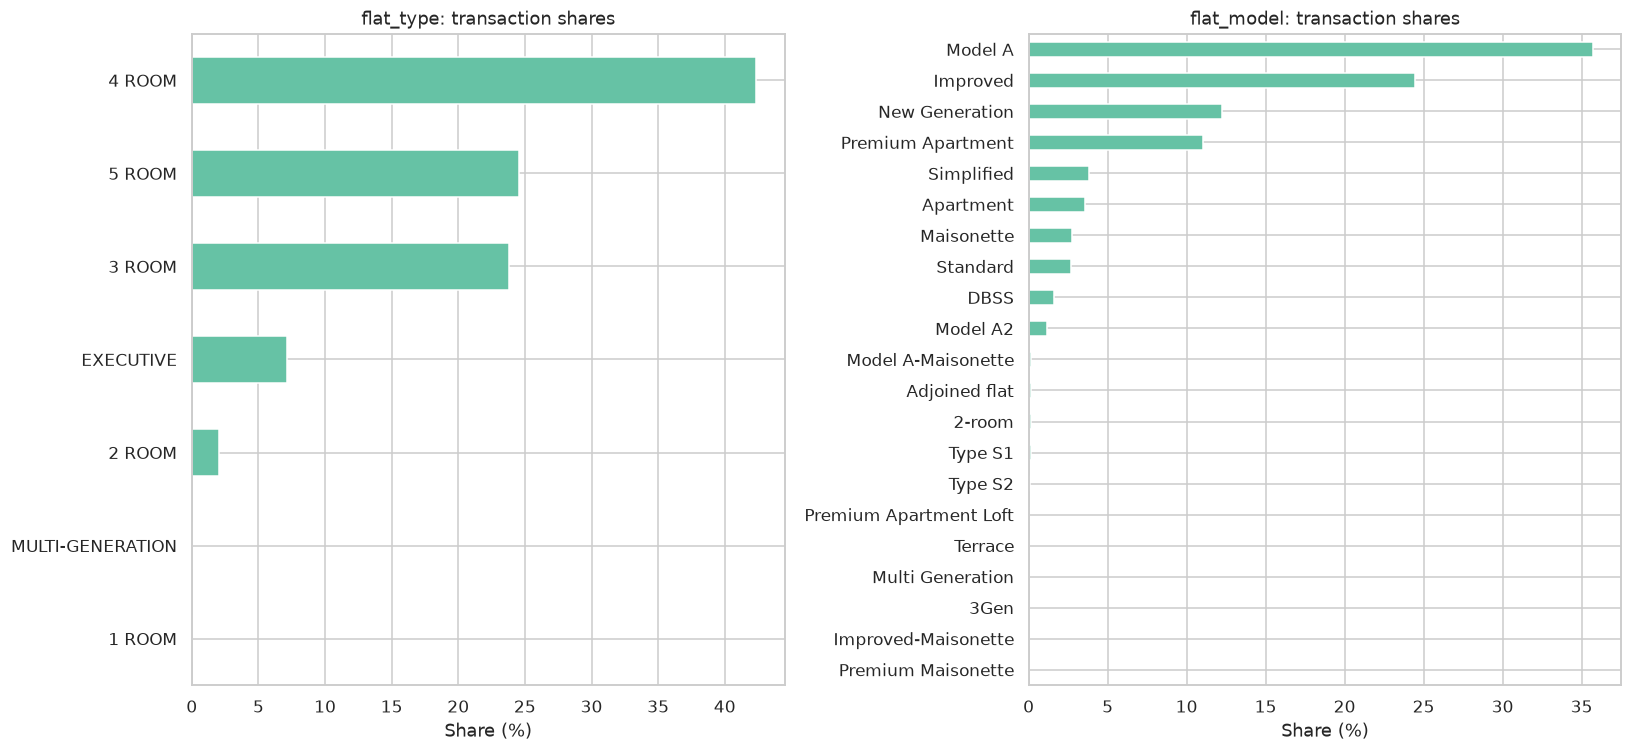

In [8]:
category_columns = ["flat_type", "flat_model"]
category_tables = {}
for column in category_columns:
    counts = df[column].value_counts()
    table = counts.rename("count").to_frame()
    table["share_pct"] = counts / len(df) * 100
    table["rare_below_1pct"] = table["share_pct"].lt(1)
    category_tables[column] = table
    print(f"Category distribution: {column}")
    display(table)

one_hot = pd.get_dummies(df[category_columns], prefix=category_columns, dtype=int)
display(one_hot.head())
display(one_hot.mean().mul(100).rename("One-hot share (%)").to_frame())
for column in category_columns:
    assert one_hot.filter(like=f"{column}_").sum(axis=1).eq(1).all()

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for column, ax in zip(category_columns, axes):
    category_tables[column]["share_pct"].sort_values().plot.barh(ax=ax)
    ax.set(title=f"{column}: transaction shares", xlabel="Share (%)", ylabel="")
plt.tight_layout()
plt.show()

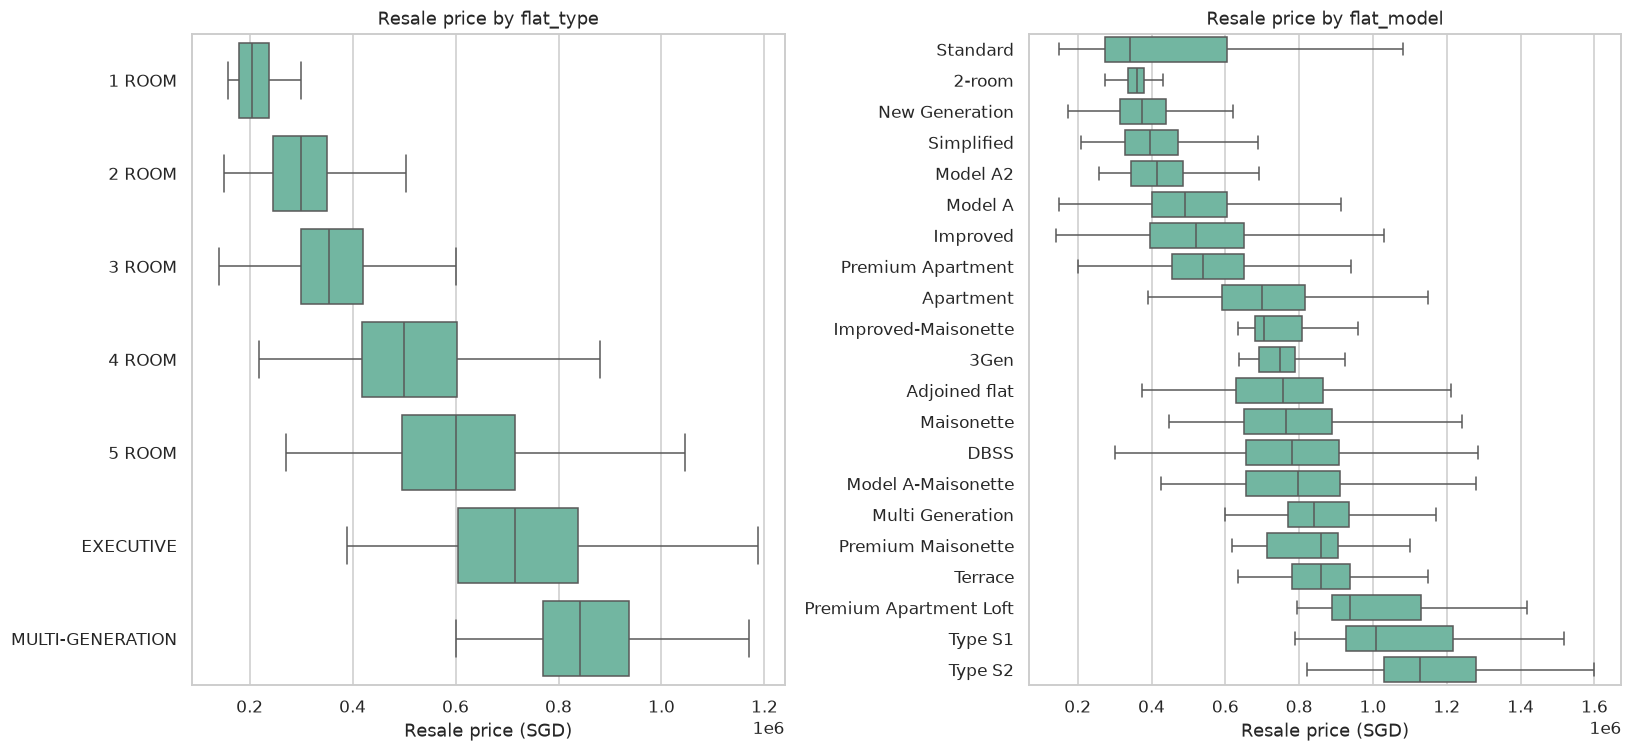

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for column, ax in zip(category_columns, axes):
    order = df.groupby(column)["resale_price"].median().sort_values().index
    sns.boxplot(data=df, y=column, x="resale_price", order=order, showfliers=False, ax=ax)
    ax.set(title=f"Resale price by {column}", xlabel="Resale price (SGD)", ylabel="")
plt.tight_layout()
plt.show()

箱线图为突出组间分布暂时隐藏离群点，**数据并未因此删除**。不同房型/模型的价格差异也可能来自面积、位置和年代，不能把组间差异直接解释为类别的因果作用。样本占比很小的类别，其相关系数与价格中位数需要谨慎解读。

## 6. 楼层区间：Ordinal Encoding 与分布

展示原始区间到 ordinal 的映射及各区间比例。编码只表达高低顺序，没有恢复精确楼层；Spearman 相关更适合检查其单调关系，Pearson 则隐含编码间距可比较的假设。原始上下界保留用于审查，不与 ordinal 同时作为模型输入。

,ordinal,lower,upper,count,median_price,share_pct
storey_range,,,,,,
01 TO 03,0,1.000,3.000,39140,445000.000,17.625
04 TO 06,1,4.000,6.000,50947,465000.000,22.942
07 TO 09,2,7.000,9.000,46591,480000.000,20.981
10 TO 12,3,10.000,12.000,41471,495000.000,18.675
13 TO 15,4,13.000,15.000,21381,540000.000,9.628
16 TO 18,5,16.000,18.000,10009,580000.000,4.507
19 TO 21,6,19.000,21.000,4303,665000.000,1.938
22 TO 24,7,22.000,24.000,3017,700000.000,1.359
25 TO 27,8,25.000,27.000,1879,755000.000,0.846


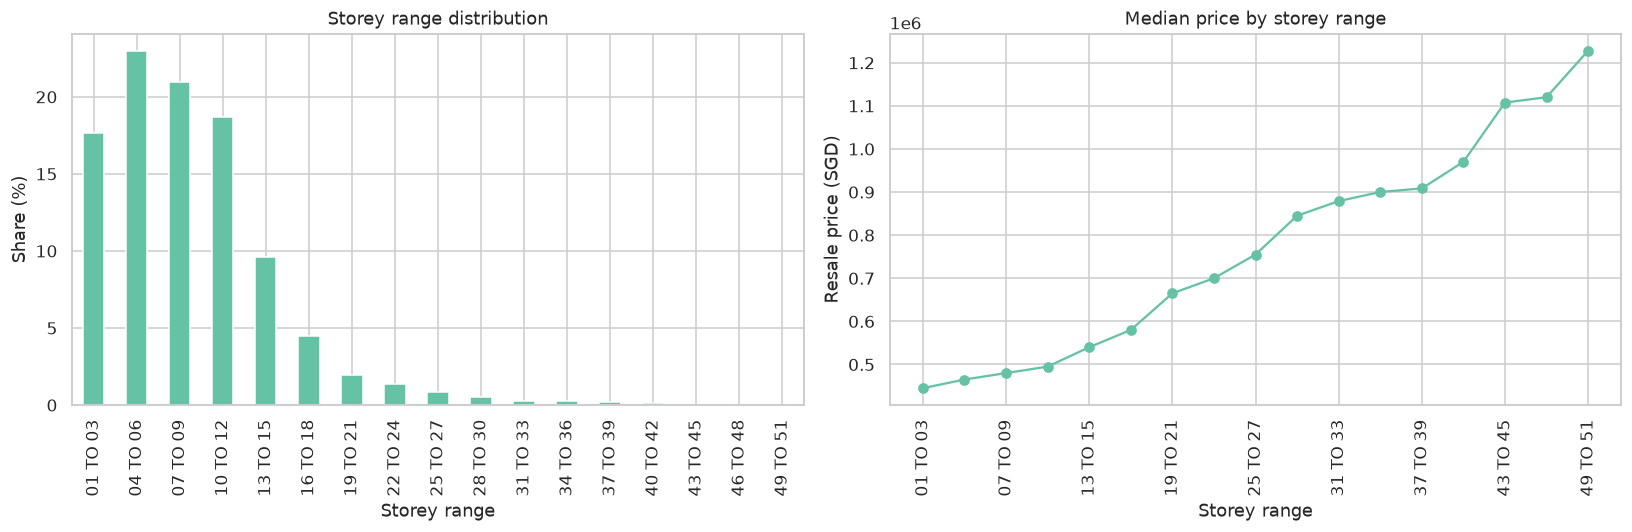

In [10]:
storey_table = df.groupby("storey_range").agg(
    ordinal=("storey_ordinal", "first"),
    lower=("storey_lower", "first"),
    upper=("storey_upper", "first"),
    count=("resale_price", "size"),
    median_price=("resale_price", "median"),
).reindex(storey_order)
storey_table["share_pct"] = storey_table["count"] / len(df) * 100
display(storey_table)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
storey_table["share_pct"].plot.bar(ax=axes[0])
axes[0].set(title="Storey range distribution", xlabel="Storey range", ylabel="Share (%)")
storey_table["median_price"].plot(marker="o", ax=axes[1])
axes[1].set(title="Median price by storey range", xlabel="Storey range", ylabel="Resale price (SGD)")
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

## 7. 地址层级：只统计，不决定编码方案

`block` 不是全岛唯一标识，不能单独当作地理实体。先统计单字段、两字段和三字段组合，观察地址层级的唯一值数量及每个组合的交易数。楼栋级单位用 **Town + Street Name + Block** 的组合表达，不将其解释为精确住宅单元。

,level,unique_combinations,min_transactions,median_transactions,max_transactions
0,town,26,542,7583.500,18155
1,street_name,576,1,277.500,3178
2,block,2745,1,51.000,669
3,town + street_name,576,1,277.500,3178
4,town + block,9097,1,21.000,177
5,street_name + block,9670,1,20.000,172
6,town + street_name + block,9670,1,20.000,172


transactions
town        street_name      block              
PUNGGOL     PUNGGOL WALK     308A            172
                             308C            154
QUEENSTOWN  DAWSON RD        87              140
PUNGGOL     PUNGGOL WALK     310B            139
TOA PAYOH   LOR 1A TOA PAYOH 139A            139
QUEENSTOWN  DAWSON RD        88              135
CLEMENTI    CLEMENTI AVE 4   311B            124
JURONG WEST BOON LAY AVE     187             123
QUEENSTOWN  DAWSON RD        86              123
PUNGGOL     PUNGGOL WALK     308B            116

,Address ambiguity
street_names_in_multiple_towns,0
block_labels_on_multiple_streets,1499


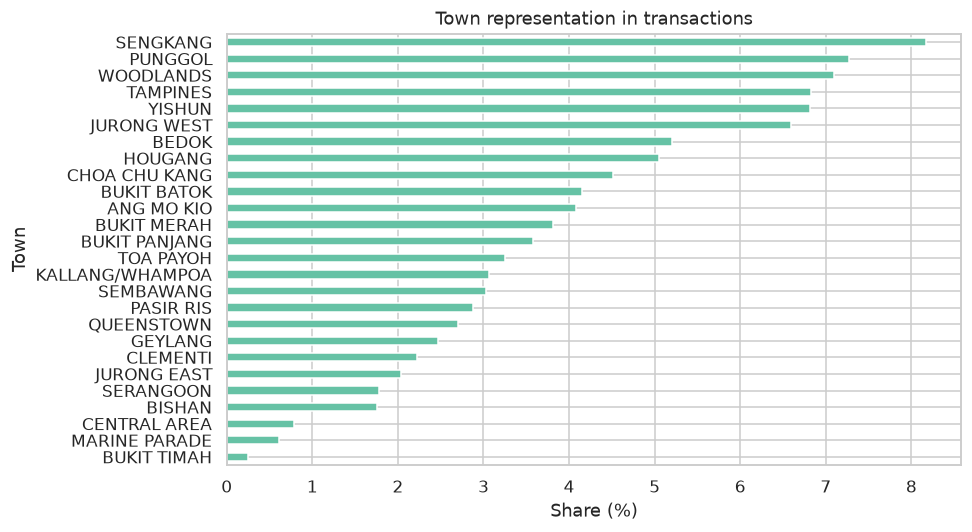

In [11]:
address_levels = [
    ["town"], ["street_name"], ["block"],
    ["town", "street_name"], ["town", "block"], ["street_name", "block"],
    ["town", "street_name", "block"],
]
address_summary = []
for columns in address_levels:
    sizes = df.groupby(columns).size()
    address_summary.append({
        "level": " + ".join(columns),
        "unique_combinations": len(sizes),
        "min_transactions": sizes.min(),
        "median_transactions": sizes.median(),
        "max_transactions": sizes.max(),
    })
address_summary = pd.DataFrame(address_summary)
display(address_summary)

address_counts = df.groupby(["town", "street_name", "block"]).size().rename("transactions")
display(address_counts.sort_values(ascending=False).head(10).to_frame())
display(pd.Series({
    "street_names_in_multiple_towns": int(df.groupby("street_name")["town"].nunique().gt(1).sum()),
    "block_labels_on_multiple_streets": int(df.groupby("block")["street_name"].nunique().gt(1).sum()),
}, name="Address ambiguity").to_frame())

fig, ax = plt.subplots(figsize=(9, 5))
df["town"].value_counts(normalize=True).mul(100).sort_values().plot.barh(ax=ax)
ax.set(title="Town representation in transactions", xlabel="Share (%)", ylabel="Town")
plt.tight_layout()
plt.show()

镇区比例描述的是交易样本覆盖，不能直接等同于镇区住房存量或人口分布。最终模型需要分别检验地区和房型上的误差；目前没有人口属性，也没有足够信息将地区当作敏感属性的直接替代。

## 8. 数值分布与统计离群值

对面积、价格、剩余租期、楼层 ordinal、月份坐标和租约开始年份分别输出统计量、直方图、箱线图及 IQR 标记。`Q1 - 1.5×IQR` 与 `Q3 + 1.5×IQR` 仅是探索阈值，**不等于数据错误或删除规则**。面积与价格的尾部样本单独展示；可对价格使用对数尺度作观察，但本次预测目标仍保留原始 SGD。

In [12]:
numeric_columns = [
    "floor_area_sqm", "resale_price", "remaining_lease_years",
    "storey_ordinal", "month_index", "lease_commence_date",
]
numeric_summary = df[numeric_columns].describe(percentiles=[.01, .25, .5, .75, .99]).T
numeric_summary["skewness"] = df[numeric_columns].skew()
display(numeric_summary)

q1 = df[numeric_columns].quantile(.25)
q3 = df[numeric_columns].quantile(.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
outlier_flags = df[numeric_columns].lt(lower_fence) | df[numeric_columns].gt(upper_fence)
outlier_summary = pd.DataFrame({
    "lower_fence": lower_fence, "upper_fence": upper_fence,
    "lower_tail_count": df[numeric_columns].lt(lower_fence).sum(),
    "upper_tail_count": df[numeric_columns].gt(upper_fence).sum(),
    "outlier_count": outlier_flags.sum(),
    "outlier_pct": outlier_flags.mean() * 100,
})
display(outlier_summary)

,count,mean,std,min,1%,25%,50%,75%,99%,max,skewness
floor_area_sqm,222066.000,96.770,24.020,31.000,47.000,81.000,93.000,112.000,151.000,366.700,0.257
resale_price,222066.000,524464.323,186593.819,140000.000,230000.000,385000.000,492000.000,630000.000,1070000.000,1658888.000,0.960
remaining_lease_years,222066.000,74.251,14.232,40.083,46.250,62.500,74.083,88.667,95.250,97.750,-0.020
storey_ordinal,222066.000,2.256,1.980,0.000,0.000,1.000,2.000,3.000,9.000,16.000,1.606
month_index,222066.000,56.193,30.182,0.000,1.000,31.000,57.000,82.000,106.000,107.000,-0.120
lease_commence_date,222066.000,1996.435,14.301,1966.000,1969.000,1985.000,1997.000,2012.000,2020.000,2021.000,0.064


,lower_fence,upper_fence,lower_tail_count,upper_tail_count,outlier_count,outlier_pct
floor_area_sqm,34.500,158.500,102,1085,1187,0.535
resale_price,17500.000,997500.000,0,4059,4059,1.828
remaining_lease_years,23.250,127.917,0,0,0,0.000
storey_ordinal,-2.000,6.000,0,8224,8224,3.703
month_index,-45.500,158.500,0,0,0,0.000
lease_commence_date,1944.500,2052.500,0,0,0,0.000


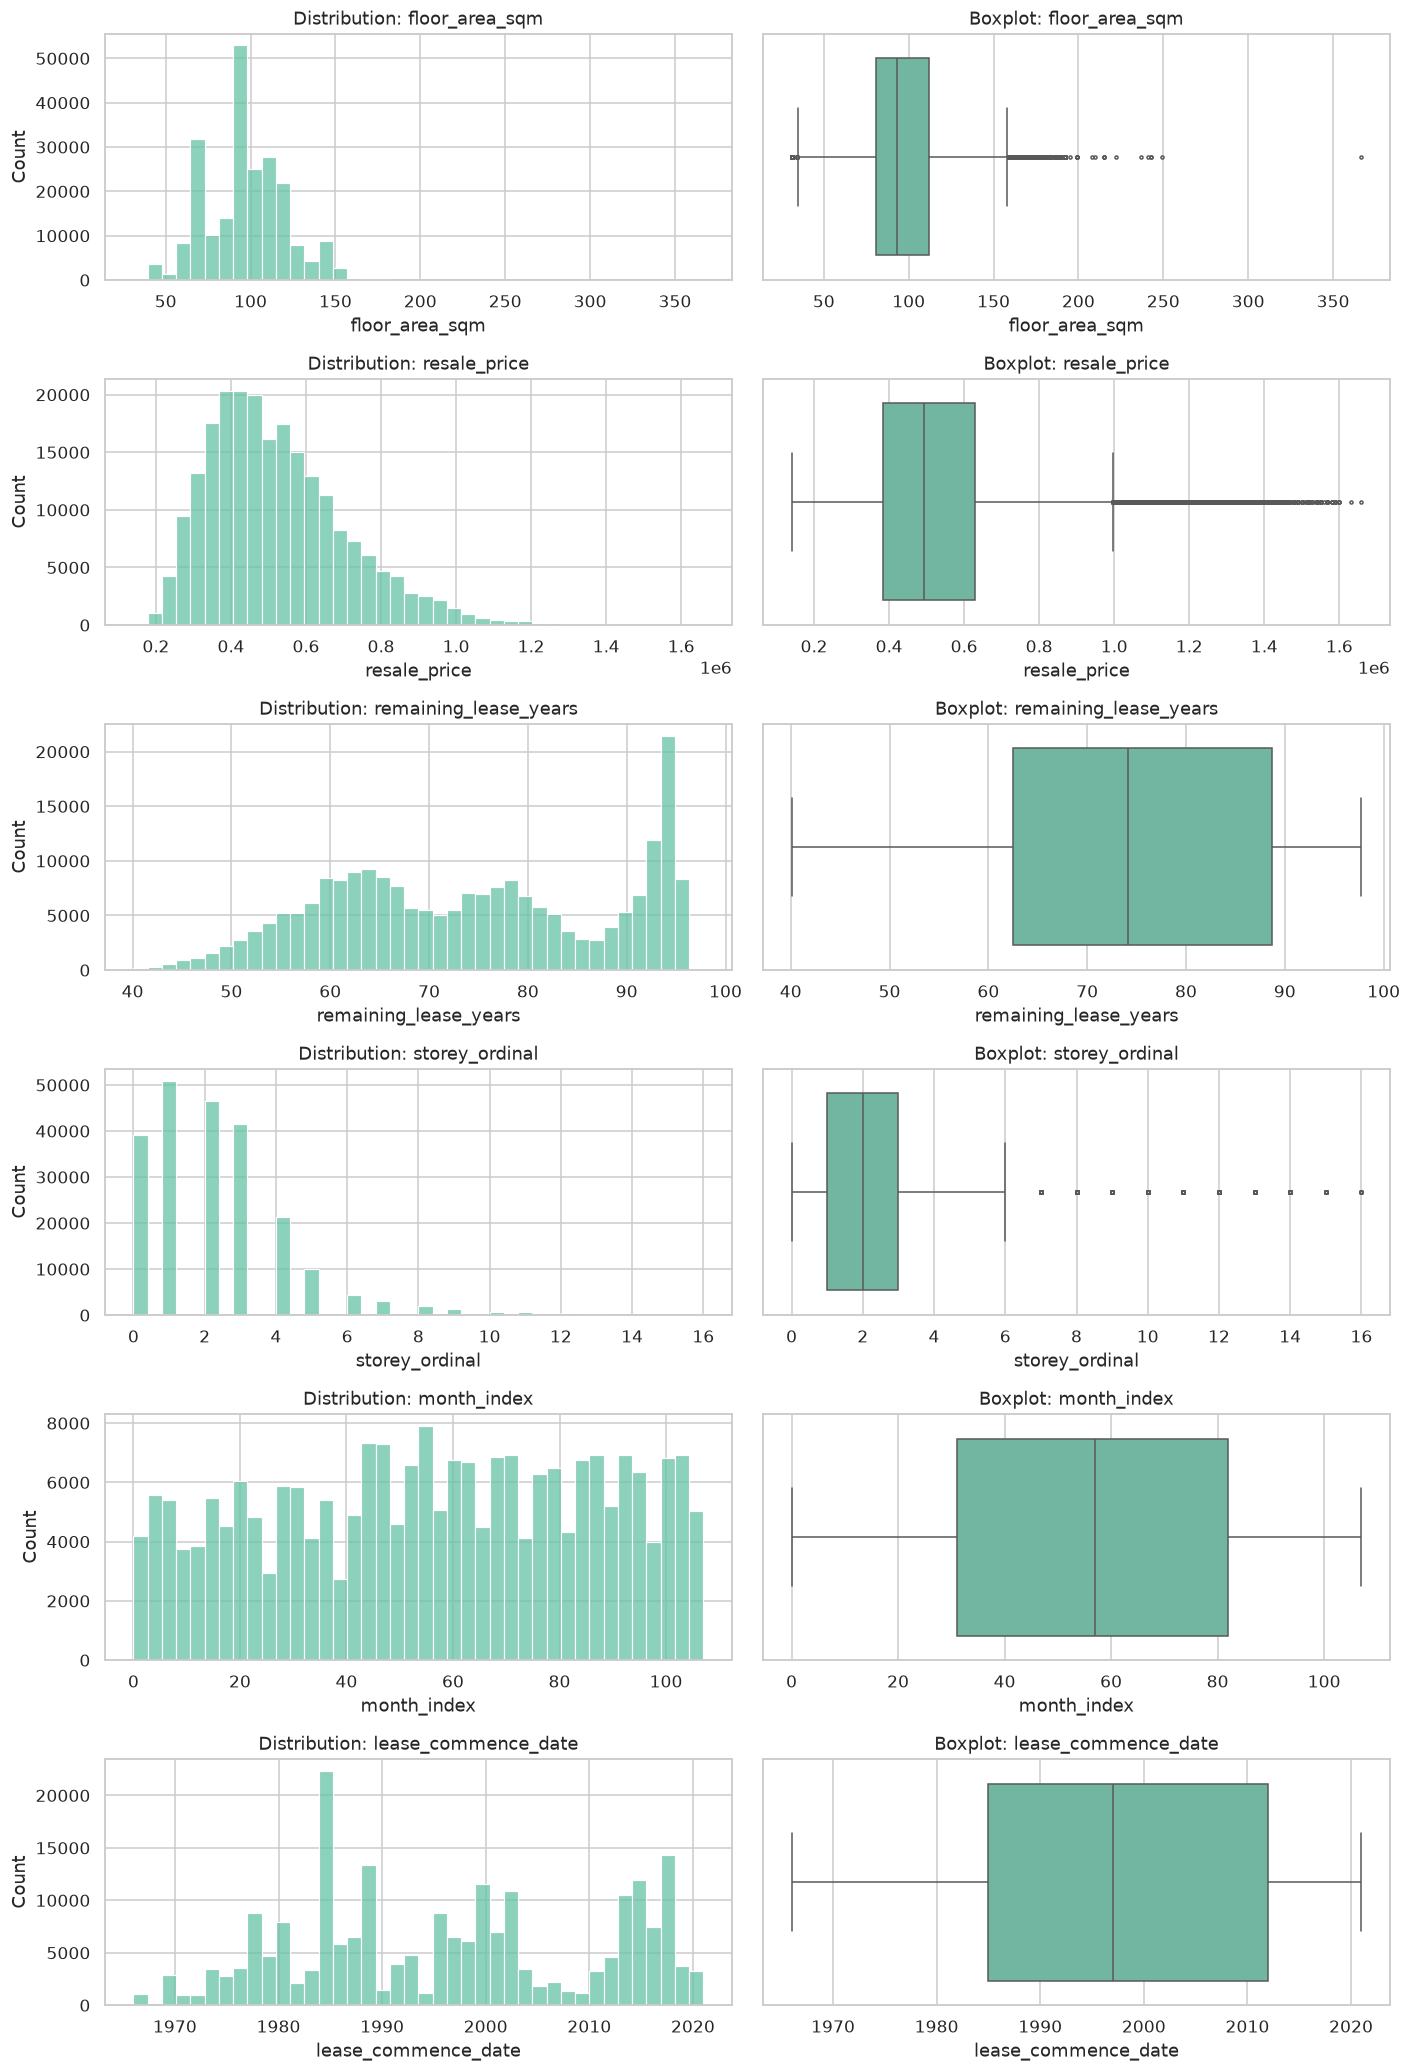

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
182823,2024-07,KALLANG/WHAMPOA,3 ROOM,53,JLN MA'MOR,01 TO 03,366.700,Terrace,1972,47 years,1568000.000
19693,2017-12,KALLANG/WHAMPOA,3 ROOM,65,JLN MA'MOR,01 TO 03,249.000,Terrace,1972,53 years 07 months,1053888.000
92512,2021-03,BISHAN,EXECUTIVE,446,BRIGHT HILL DR,07 TO 09,243.000,Maisonette,1990,68 years 01 month,1092888.000
94959,2021-04,BISHAN,EXECUTIVE,454,SIN MING AVE,10 TO 12,243.000,Maisonette,1989,67 years 08 months,1001000.000
107851,2021-09,KALLANG/WHAMPOA,3 ROOM,46,JLN BAHAGIA,01 TO 03,241.000,Terrace,1972,49 years 10 months,1235000.000
35797,2018-09,KALLANG/WHAMPOA,3 ROOM,41,JLN BAHAGIA,01 TO 03,237.000,Terrace,1972,52 years 10 months,1185000.000
95808,2021-04,KALLANG/WHAMPOA,3 ROOM,61,JLN TENTERAM,01 TO 03,222.000,Terrace,1972,50 years 03 months,1100000.000
8868,2017-06,KALLANG/WHAMPOA,3 ROOM,38,JLN BAHAGIA,01 TO 03,215.000,Terrace,1972,54 years 01 month,830000.000


,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
212073,2025-06,QUEENSTOWN,5 ROOM,92,DAWSON RD,22 TO 24,122.000,Premium Apartment Loft,2016,89 years 11 months,1658888.000
199476,2025-11,BISHAN,5 ROOM,275A,BISHAN ST 24,34 TO 36,120.000,DBSS,2011,84 years 10 months,1632000.000
199498,2025-11,BISHAN,EXECUTIVE,135,BISHAN ST 12,22 TO 24,163.000,Maisonette,1987,60 years 08 months,1600000.000
202785,2025-08,CENTRAL AREA,5 ROOM,1G,CANTONMENT RD,49 TO 51,105.000,Type S2,2011,84 years 05 months,1600000.000
218475,2025-01,TOA PAYOH,5 ROOM,138A,LOR 1A TOA PAYOH,19 TO 21,117.000,DBSS,2012,86 years 06 months,1600000.000
202786,2025-09,CENTRAL AREA,5 ROOM,1A,CANTONMENT RD,40 TO 42,107.000,Type S2,2011,84 years 04 months,1590000.000
174171,2024-06,BUKIT MERAH,5 ROOM,9B,BOON TIONG RD,34 TO 36,112.000,Improved,2016,90 years 08 months,1588000.000
174172,2024-06,BUKIT MERAH,5 ROOM,96A,HENDERSON RD,46 TO 48,113.000,Improved,2019,94 years,1588000.000


In [13]:
fig, axes = plt.subplots(len(numeric_columns), 2, figsize=(13, 19))
for column, row in zip(numeric_columns, axes):
    sns.histplot(data=df, x=column, bins=40, ax=row[0])
    row[0].set_title(f"Distribution: {column}")
    sns.boxplot(data=df, x=column, ax=row[1], fliersize=2)
    row[1].set_title(f"Boxplot: {column}")
plt.tight_layout()
plt.show()

display(df.nlargest(8, "floor_area_sqm")[list(raw.columns)])
display(df.nlargest(8, "resale_price")[list(raw.columns)])

,q1,q3,count,lower_fence,upper_fence,within_type_outlier_count
flat_type,,,,,,
1 ROOM,31.000,31.000,80,31.000,31.000,0
2 ROOM,45.000,47.000,4496,42.000,50.000,631
3 ROOM,65.000,70.000,52871,57.500,77.500,4032
4 ROOM,91.000,101.000,94091,76.000,116.000,305
5 ROOM,112.000,122.000,54509,97.000,137.000,752
EXECUTIVE,141.000,148.000,15935,130.500,158.500,2957
MULTI-GENERATION,159.000,166.750,84,147.375,178.375,22


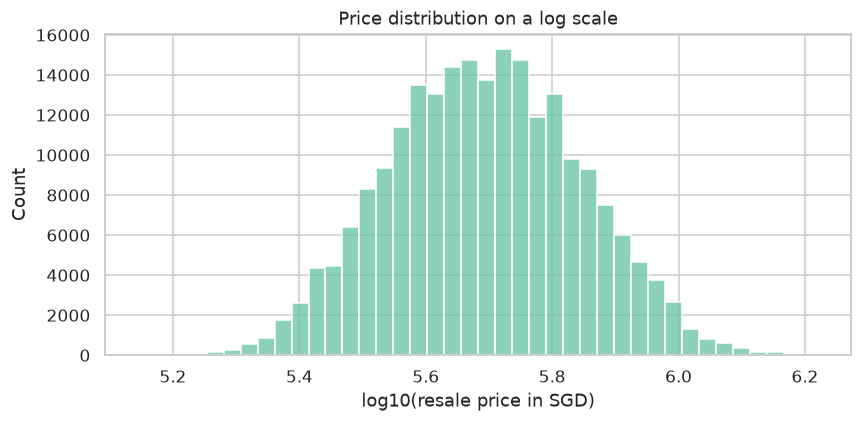

In [14]:
type_outliers = df.groupby("flat_type")["floor_area_sqm"].agg(
    q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75), count="size"
)
type_outliers["lower_fence"] = type_outliers["q1"] - 1.5 * (type_outliers["q3"] - type_outliers["q1"])
type_outliers["upper_fence"] = type_outliers["q3"] + 1.5 * (type_outliers["q3"] - type_outliers["q1"])
within_type_area_outlier = (
    df["floor_area_sqm"].lt(df["flat_type"].map(type_outliers["lower_fence"]))
    | df["floor_area_sqm"].gt(df["flat_type"].map(type_outliers["upper_fence"]))
)
type_outliers["within_type_outlier_count"] = within_type_area_outlier.groupby(df["flat_type"]).sum()
display(type_outliers)

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(np.log10(df["resale_price"]), bins=40, ax=ax)
ax.set(title="Price distribution on a log scale", xlabel="log10(resale price in SGD)")
plt.tight_layout()
plt.show()

全局面积 IQR 和同房型面积 IQR 是两个不同的参照：前者受房型构成影响，后者提示同类中的罕见记录。样本稀少或四分位数接近的类别会产生很窄的阈值，不能据此断言录入错误。后续如要删除/截尾，应使用训练集确定阈值，并用同一个基础模型比较其影响。

## 9. 租期冗余与跨字段一致性

使用用户提出的近似公式：`expected_lease_years = 99 - (transaction_year - lease_commence_date)`，并计算 **记录剩余租期 − 近似值**。

租约开始字段只有年份，剩余租期有月份；登记日期也不一定是租期计量日期。因此残差不应要求严格等于 0。这里把绝对差超过 1 年标为“需要查看”，超过 2 年标为“明显偏离”；它们是诊断阈值，并非官方错误标准。展示正负方向、月份集中情况和同栋历史交易，保留原始值，避免用近似公式强制覆盖精确信息。

`lease_commence_date` 可以在未来模型中排除，但它只是在月份坐标和剩余租期已存在时**近似冗余**，不是完全相同的信息。本次仍计算它与价格及其他数值字段的相关性，以提供排除依据。

In [15]:
df["expected_lease_years"] = 99 - (df["transaction_year"] - df["lease_commence_date"])
df["lease_residual_years"] = df["remaining_lease_years"] - df["expected_lease_years"]
df["lease_formula_review"] = df["lease_residual_years"].abs().gt(1 + 1e-8)
df["lease_formula_severe"] = df["lease_residual_years"].abs().gt(2)

display(df[["expected_lease_years", "remaining_lease_years", "lease_residual_years"]].describe())
display(pd.Series({
    "exact_matches": int(df["lease_residual_years"].abs().lt(1e-8).sum()),
    "within_one_year": int((~df["lease_formula_review"]).sum()),
    "review_over_one_year": int(df["lease_formula_review"].sum()),
    "positive_residual_over_one_year": int(df["lease_residual_years"].gt(1 + 1e-8).sum()),
    "negative_residual_below_minus_one_year": int(df["lease_residual_years"].lt(-1 - 1e-8).sum()),
    "severe_over_two_years": int(df["lease_formula_severe"].sum()),
}, name="Lease formula audit").to_frame())

lease_review = df.loc[df["lease_formula_review"]]
display(lease_review.groupby(df.loc[lease_review.index, "transaction_date"].dt.month).agg(
    count=("resale_price", "size"),
    min_residual=("lease_residual_years", "min"),
    max_residual=("lease_residual_years", "max"),
).rename_axis("Registration calendar month"))
display(lease_review.sort_values("lease_residual_years")[
    ["month", "town", "street_name", "block", "lease_commence_date",
     "remaining_lease", "expected_lease_years", "lease_residual_years", "resale_price"]
].head(15))

,expected_lease_years,remaining_lease_years,lease_residual_years
count,222066.000,222066.000,222066.000
mean,74.220,74.251,0.031
std,14.200,14.232,0.406
min,40.000,40.083,-14.917
25%,62.000,62.500,-0.250
50%,74.000,74.083,0.000
75%,89.000,88.667,0.333
max,98.000,97.750,1.167


,Lease formula audit
exact_matches,17291
within_one_year,221938
review_over_one_year,128
positive_residual_over_one_year,127
negative_residual_below_minus_one_year,1
severe_over_two_years,1


,count,min_residual,max_residual
Registration calendar month,,,
1,126,-14.917,1.167
2,2,1.167,1.167


,month,town,street_name,block,lease_commence_date,remaining_lease,expected_lease_years,lease_residual_years,resale_price
206481,2025-01,JURONG EAST,TEBAN GDNS RD,37,1981,40 years 01 month,55,-14.917,350000.000
20645,2018-01,BUKIT BATOK,BT BATOK WEST AVE 6,135,1984,66 years 01 month,65,1.083,270000.000
20981,2018-01,JURONG WEST,JURONG WEST AVE 3,273A,2001,83 years 01 month,82,1.083,370000.000
20748,2018-01,BUKIT PANJANG,LOMPANG RD,179,2001,83 years 01 month,82,1.083,450000.000
43335,2019-01,TOA PAYOH,KIM KEAT LINK,249,1988,69 years 01 month,68,1.083,470000.000
88053,2021-01,BUKIT PANJANG,SEGAR RD,485,2014,93 years 01 month,92,1.083,324000.000
88093,2021-01,BUKIT PANJANG,FAJAR RD,443C,2016,95 years 01 month,94,1.083,445000.000
21246,2018-01,SENGKANG,SENGKANG CTRL,272A,2009,91 years 01 month,90,1.083,405000.000
88943,2021-01,PUNGGOL,EDGEFIELD PLAINS,671A,2015,94 years 01 month,93,1.083,405000.000
89369,2021-01,SENGKANG,RIVERVALE CRES,155,2005,84 years 01 month,83,1.083,448000.000


,month,town,street_name,block,flat_type,lease_commence_date,remaining_lease,lease_residual_years,resale_price
0,2017-01,JURONG EAST,TEBAN GDNS RD,37,3 ROOM,1966,48 years 09 months,0.750,250000.000
1,2017-10,JURONG EAST,TEBAN GDNS RD,37,3 ROOM,1966,48 years,0.000,200000.000
2,2017-11,JURONG EAST,TEBAN GDNS RD,37,3 ROOM,1966,48 years,0.000,232000.000
3,2018-06,JURONG EAST,TEBAN GDNS RD,37,3 ROOM,1966,47 years 04 months,0.333,226000.000
4,2018-09,JURONG EAST,TEBAN GDNS RD,37,3 ROOM,1966,47 years 02 months,0.167,215000.000
5,2020-01,JURONG EAST,TEBAN GDNS RD,37,3 ROOM,1966,45 years 09 months,0.750,220000.000
6,2020-12,JURONG EAST,TEBAN GDNS RD,37,3 ROOM,1966,44 years 10 months,-0.167,230000.000
7,2024-05,JURONG EAST,TEBAN GDNS RD,37,3 ROOM,1966,41 years 06 months,0.500,340000.000
8,2025-01,JURONG EAST,TEBAN GDNS RD,37,3 ROOM,1981,40 years 01 month,-14.917,350000.000
9,2025-06,JURONG EAST,TEBAN GDNS RD,37,3 ROOM,1966,40 years 05 months,0.417,360000.000


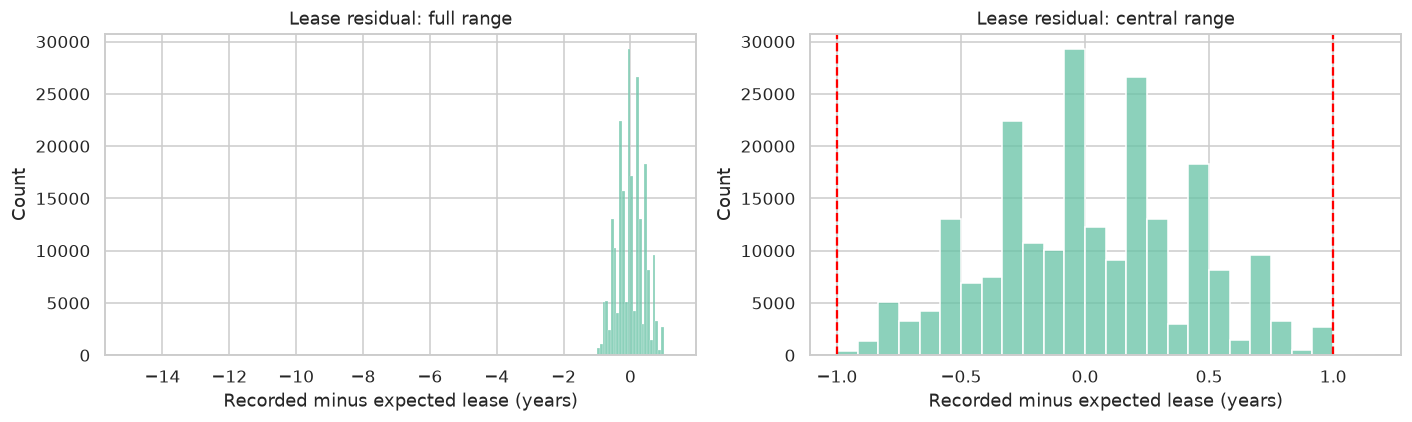

In [16]:
severe_addresses = df.loc[df["lease_formula_severe"], ["town", "street_name", "block"]].drop_duplicates()
address_history = df.merge(severe_addresses, on=["town", "street_name", "block"])
display(address_history.sort_values("month").tail(20)[
    ["month", "town", "street_name", "block", "flat_type", "lease_commence_date",
     "remaining_lease", "lease_residual_years", "resale_price"]
])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="lease_residual_years", binwidth=1/12, ax=axes[0])
axes[0].set(title="Lease residual: full range", xlabel="Recorded minus expected lease (years)")
sns.histplot(data=df.loc[~df["lease_formula_severe"]], x="lease_residual_years", binwidth=1/12, ax=axes[1])
axes[1].axvline(-1, color="red", linestyle="--")
axes[1].axvline(1, color="red", linestyle="--")
axes[1].set(title="Lease residual: central range", xlabel="Recorded minus expected lease (years)")
plt.tight_layout()
plt.show()

当前快照的非显然发现：按 ±1 年筛查有 **128 条**记录，127 条为略大于 +1 年的偏差，1 条为约 **−14.92 年**。前一类可以提出“年份精度或计量时点不同”的待验证解释；后一类是 `2025-01 / JURONG EAST / TEBAN GDNS RD / 37`，租约开始 1981 年、剩余租期 `40 years 01 month`，应结合同栋记录及官方核查进一步调查。**目前不能确认哪个字段错误，也不能认定整栋租期必然相同，因此不擅自修改。**

这个发现展示了：只看剩余租期自己的分布，它可能没有 IQR 离群；但跨字段关系能揭示问题。上述数字对应随附快照，刷新后应重新核对文字。

## 10. 登记时间：连续编码、月度趋势与时间覆盖

按年月排序展示交易数、价格中位数、面积中位数与剩余租期中位数。检查 108 个月是否齐全。月份坐标适合描述时间趋势，但**不等于随机独立样本**；后续模型应按时间切分，所有训练所需的拟合操作只使用训练集。

,Time coverage
observed_months,108
expected_months,108
missing_months,0
month_index_min,0
month_index_max,107


,transactions,median_price,median_area,median_remaining_lease
transaction_date,,,,
2017-01-01,1185,405000.000,95.000,71.667
2017-02-01,1085,415000.000,96.000,74.500
2017-03-01,1903,415000.000,95.000,74.583
2017-04-01,1839,408000.000,95.000,74.000
2017-05-01,1980,410000.000,96.000,74.583


,transactions,median_price,median_area,median_remaining_lease
transaction_date,,,,
2025-08-01,2202,622000.000,93.000,71.667
2025-09-01,2174,645000.000,93.000,72.250
2025-10-01,1338,620000.000,93.000,70.625
2025-11-01,1658,618000.000,93.000,71.083
2025-12-01,2024,635000.000,93.000,71.083


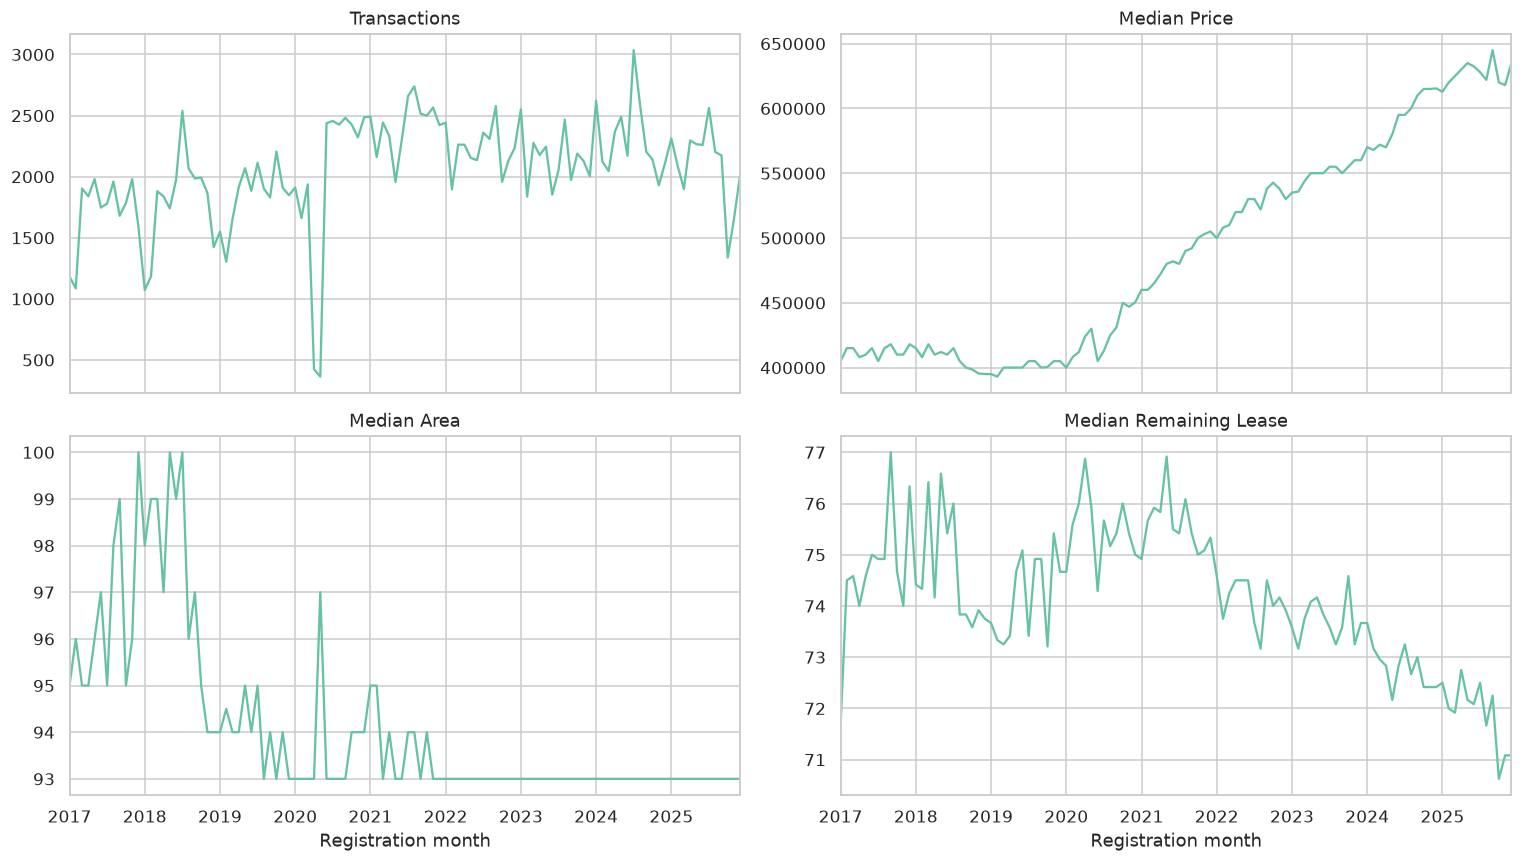

In [17]:
monthly = df.groupby("transaction_date").agg(
    transactions=("resale_price", "size"),
    median_price=("resale_price", "median"),
    median_area=("floor_area_sqm", "median"),
    median_remaining_lease=("remaining_lease_years", "median"),
)
expected_months = pd.date_range("2017-01-01", "2025-12-01", freq="MS")
display(pd.Series({
    "observed_months": len(monthly),
    "expected_months": len(expected_months),
    "missing_months": len(expected_months.difference(monthly.index)),
    "month_index_min": df["month_index"].min(),
    "month_index_max": df["month_index"].max(),
}, name="Time coverage").to_frame())
display(monthly.head())
display(monthly.tail())

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for column, ax in zip(monthly.columns, axes.flat):
    monthly[column].plot(ax=ax)
    ax.set(title=column.replace("_", " ").title(), xlabel="Registration month")
plt.tight_layout()
plt.show()

## 11. 与价格的相关性：Pearson、Spearman 与类别指示变量

除地址外，将编码后的类别、面积、剩余租期、楼层 ordinal、连续月份和租约开始年份与价格关联。`transaction_year` 不重复加入，因为已由 `month_index` 表达；楼层上下界也不重复加入。

Pearson 描述线性关系，Spearman 描述秩的单调关系。One-hot 每列的 Pearson 是“属于该类别”与价格的关联；类别本身没有一个天然的连续相关系数。相关性不等于因果关系，缺少地址可能造成混杂；这里也不将相关系数大小直接解释为模型重要性。

,pearson,spearman,kind
floor_area_sqm,0.572,0.610,continuous_or_ordinal
flat_type_3 ROOM,-0.458,-0.520,one_hot
month_index,0.396,0.420,continuous_or_ordinal
lease_commence_date,0.371,0.412,continuous_or_ordinal
storey_ordinal,0.342,0.247,continuous_or_ordinal
flat_type_EXECUTIVE,0.308,0.298,one_hot
remaining_lease_years,0.304,0.328,continuous_or_ordinal
flat_type_5 ROOM,0.303,0.334,one_hot
flat_model_New Generation,-0.281,-0.313,one_hot
flat_model_Maisonette,0.230,0.206,one_hot


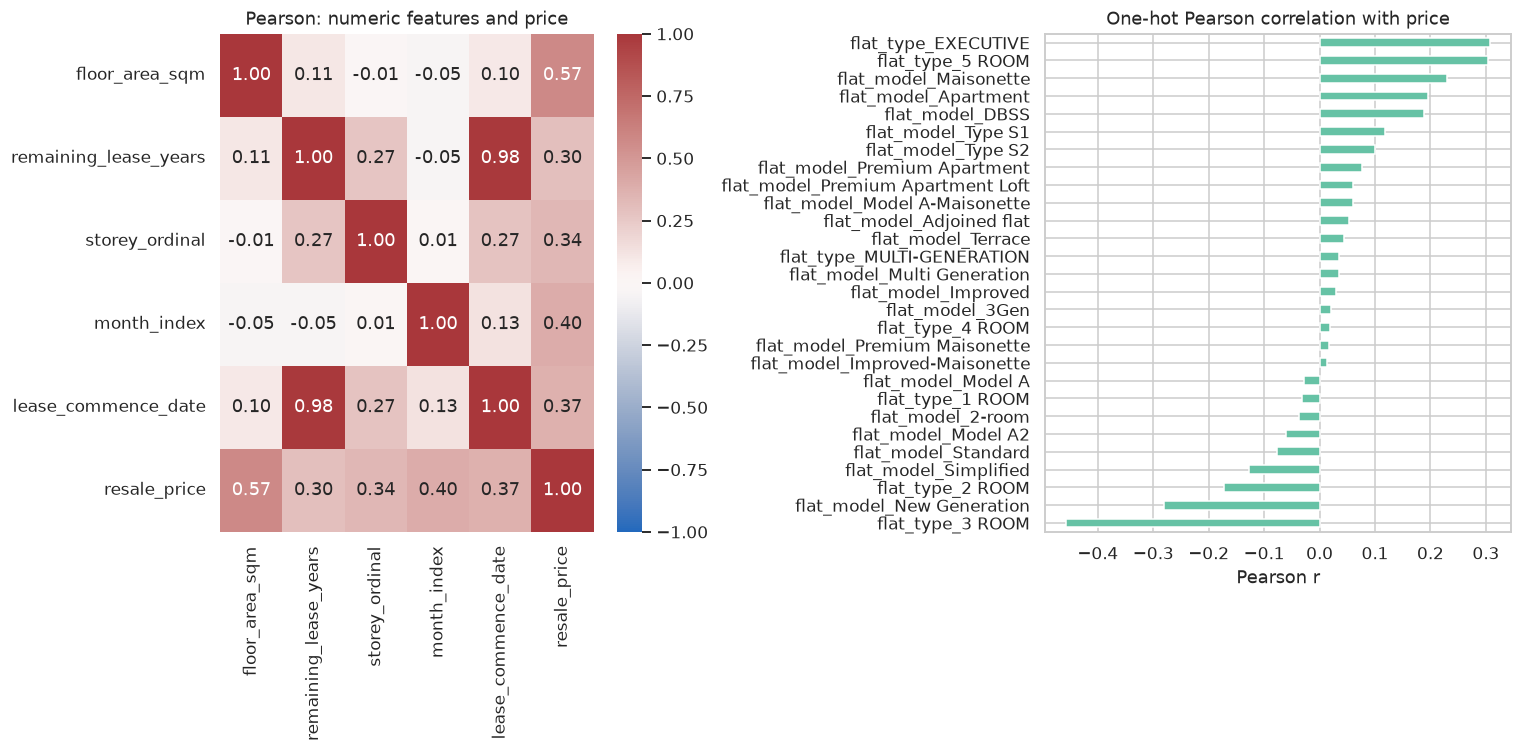

In [18]:
continuous_features = [
    "floor_area_sqm", "remaining_lease_years", "storey_ordinal",
    "month_index", "lease_commence_date",
]
encoded = pd.concat([df[continuous_features], one_hot], axis=1)
price_correlations = pd.DataFrame({
    "pearson": encoded.corrwith(df["resale_price"], method="pearson"),
    "spearman": encoded.corrwith(df["resale_price"], method="spearman"),
})
price_correlations["kind"] = ["continuous_or_ordinal" if c in continuous_features else "one_hot" for c in encoded.columns]
price_correlations = price_correlations.loc[
    price_correlations["pearson"].abs().sort_values(ascending=False).index
]
display(price_correlations)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
numeric_corr = df[continuous_features + ["resale_price"]].corr()
sns.heatmap(numeric_corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson: numeric features and price")
price_correlations.loc[one_hot.columns, "pearson"].sort_values().plot.barh(ax=axes[1])
axes[1].set(title="One-hot Pearson correlation with price", xlabel="Pearson r", ylabel="")
plt.tight_layout()
plt.show()

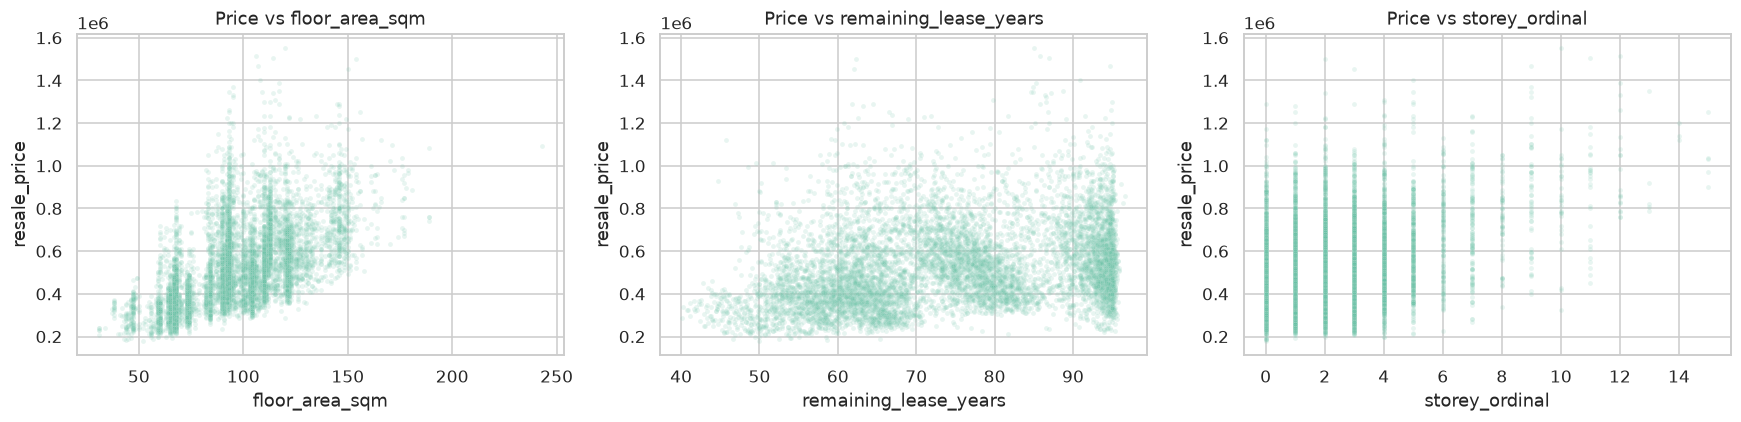

In [19]:
sample = df.sample(n=min(8000, len(df)), random_state=42)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for column, ax in zip(["floor_area_sqm", "remaining_lease_years", "storey_ordinal"], axes):
    sns.scatterplot(data=sample, x=column, y="resale_price", alpha=.15, s=10, ax=ax)
    ax.set_title(f"Price vs {column}")
plt.tight_layout()
plt.show()

### 11.1 总体相关与组内相关

面积、房型、年份彼此相关。把所有交易合并得到的相关性，可能与同房型或同年的关系不同。分别计算组内面积/租期与价格的 Pearson 相关，用于检验组成效应；**仅在看到方向反转并调查原因后，才能称为 Simpson's paradox**。

当前快照的总体面积–价格相关约 0.572，但 4 ROOM 内约 −0.061，5 ROOM 内约 0.013。不能据总体结果断言同房型中面积增加就会带来同等程度的价格上升。进一步按 4 ROOM 的模型标签查看面积、剩余租期和价格中位数，调查是否存在年代/模型构成差异；地址混杂还需要下一阶段处理。1 ROOM 的面积没有变化，其面积相关系数没有定义，表中显示 NaN 并不意味着原字段缺失。

,grouping,group,count,area_price_pearson,lease_price_pearson
0,flat_type,1 ROOM,80,NaN,-0.799
1,flat_type,2 ROOM,4496,0.138,0.445
2,flat_type,3 ROOM,52871,0.236,0.435
3,flat_type,4 ROOM,94091,-0.061,0.321
4,flat_type,5 ROOM,54509,0.013,0.086
5,flat_type,EXECUTIVE,15935,0.346,-0.520
6,flat_type,MULTI-GENERATION,84,0.305,-0.638
7,transaction_year,2017,20509,0.634,0.351
8,transaction_year,2018,21561,0.631,0.321
9,transaction_year,2019,22186,0.635,0.315


,count,median_area,median_lease,median_price
flat_model,,,,
Model A,58121,94.000,80.750,520000.000
Premium Apartment,12853,93.000,89.417,526000.000
New Generation,9920,92.000,59.500,448000.000
Simplified,6239,84.000,64.667,420000.000
Model A2,2512,90.000,77.667,416000.000
Improved,2405,84.000,53.250,460000.000
DBSS,1468,91.000,91.667,738000.000
Type S1,360,94.000,88.500,1009000.000
Premium Apartment Loft,95,97.000,93.917,938000.000


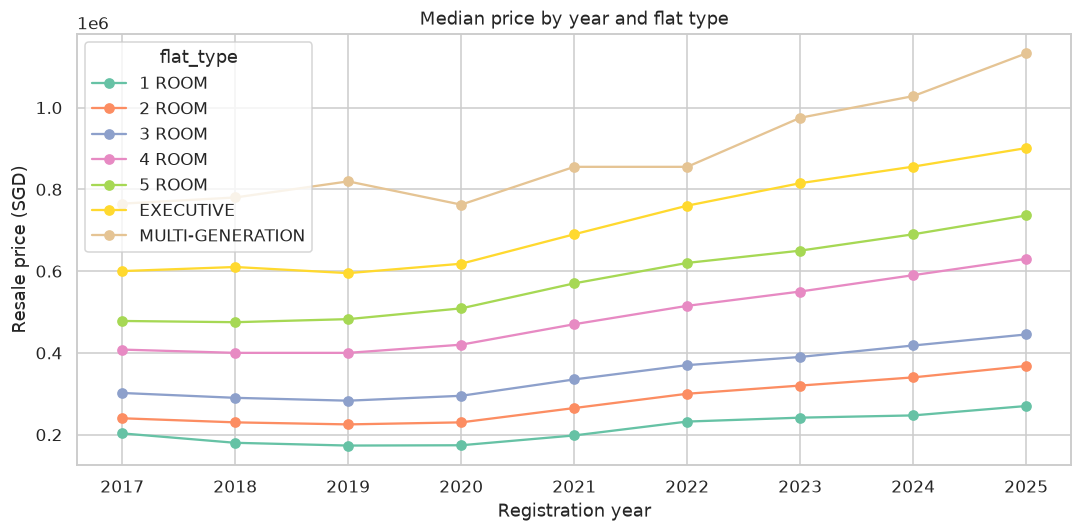

In [20]:
group_correlations = []
for grouping in ["flat_type", "transaction_year"]:
    for group, part in df.groupby(grouping):
        correlations = part[["floor_area_sqm", "remaining_lease_years", "resale_price"]].corr()["resale_price"]
        group_correlations.append({
            "grouping": grouping, "group": str(group), "count": len(part),
            "area_price_pearson": correlations["floor_area_sqm"],
            "lease_price_pearson": correlations["remaining_lease_years"],
        })
group_correlations = pd.DataFrame(group_correlations)
display(group_correlations)

four_room_models = df.loc[df["flat_type"].eq("4 ROOM")].groupby("flat_model").agg(
    count=("resale_price", "size"),
    median_area=("floor_area_sqm", "median"),
    median_lease=("remaining_lease_years", "median"),
    median_price=("resale_price", "median"),
).sort_values("count", ascending=False)
display(four_room_models)

year_type_prices = df.pivot_table(
    index="transaction_year", columns="flat_type", values="resale_price", aggfunc="median"
)
fig, ax = plt.subplots(figsize=(10, 5))
year_type_prices.plot(marker="o", ax=ax)
ax.set(title="Median price by year and flat type", xlabel="Registration year", ylabel="Resale price (SGD)")
plt.tight_layout()
plt.show()

### 11.2 敏感性比较：重复行、租期异常与价格尾部

主分析保留完全重复行及合理范围内的统计离群值。另计算三个独立对照：去掉完全重复的额外行、去掉明显偏离租期公式的记录、仅保留价格 IQR 范围。第三项是**截断目标分布**的描述性实验，会改变研究总体和相关性，不能因为结果“更好看”就作为默认清洗方案。这里尚未证明这些处理会改善模型表现。

In [21]:
variants = {
    "all_valid_rows": pd.Series(True, index=df.index),
    "deduplicated": ~df.duplicated(subset=list(raw.columns)),
    "exclude_severe_lease_residual": ~df["lease_formula_severe"],
    "price_inside_global_IQR": ~outlier_flags["resale_price"],
}
sensitivity = []
for name, mask in variants.items():
    part = df.loc[mask]
    for feature in continuous_features:
        sensitivity.append({
            "variant": name, "rows": len(part), "feature": feature,
            "pearson": part[feature].corr(part["resale_price"]),
            "spearman": part[feature].corr(part["resale_price"], method="spearman"),
        })
sensitivity = pd.DataFrame(sensitivity)
display(sensitivity.pivot(index="feature", columns="variant", values="pearson"))
display(sensitivity.groupby("variant")["rows"].first().to_frame())

variant,all_valid_rows,deduplicated,exclude_severe_lease_residual,price_inside_global_IQR
feature,,,,
floor_area_sqm,0.572,0.572,0.572,0.591
lease_commence_date,0.371,0.371,0.371,0.376
month_index,0.396,0.396,0.396,0.383
remaining_lease_years,0.304,0.304,0.304,0.311
storey_ordinal,0.342,0.342,0.342,0.287


,rows
variant,
all_valid_rows,222066
deduplicated,221757
exclude_severe_lease_residual,222065
price_inside_global_IQR,218007


## 12. 保存结果与当前阶段结论

保留两类数据：带地址和审查标记的清洗表，以及仅包含当前可用数值/OHE 特征及目标的分析表。分析表排除地址与 `lease_commence_date`，保留月份和剩余租期；它是后续建模的候选输入，尚未实施训练/测试划分、缩放或基准类别删除。

所有导出都覆盖同名文件，不追加记录；保存原快照行号用于回查。类别编码采用本次探索中观察到的类别，后续时间切分时要重新在训练集确定类别与预处理参数，处理测试期新类别。

In [22]:
model_feature_columns = [c for c in encoded.columns if c != "lease_commence_date"]
model_candidates = pd.concat([encoded[model_feature_columns], df[["resale_price"]]], axis=1)
df.to_csv(OUTPUT / "hdb_cleaned.csv", index_label="source_row")
model_candidates.to_csv(OUTPUT / "hdb_encoded_candidates.csv", index_label="source_row")
quality.to_csv(OUTPUT / "literal_quality.csv", index_label="field")
numeric_summary.to_csv(OUTPUT / "numeric_summary.csv", index_label="field")
outlier_summary.to_csv(OUTPUT / "iqr_summary.csv", index_label="field")
address_summary.to_csv(OUTPUT / "address_levels.csv", index=False)
price_correlations.to_csv(OUTPUT / "price_correlations.csv", index_label="feature")
group_correlations.to_csv(OUTPUT / "group_correlations.csv", index=False)
sensitivity.to_csv(OUTPUT / "correlation_sensitivity.csv", index=False)
lease_review.to_csv(OUTPUT / "lease_formula_review.csv", index_label="source_row")
audit_flags = outlier_flags.add_prefix("iqr_").join(
    df[["lease_formula_review", "lease_formula_severe"]]
)
audit_flags.to_csv(OUTPUT / "row_audit_flags.csv", index_label="source_row")

assert df["transaction_date"].between("2017-01-01", "2025-12-31").all()
assert model_candidates.notna().all().all()
assert len(model_candidates) == len(df)
assert len(storey_mapping) == df["storey_range"].nunique()
display(model_candidates.head())
display(pd.Series({
    "analysis_rows": len(df),
    "candidate_features": len(model_feature_columns),
    "categorical_one_hot_features": one_hot.shape[1],
    "invalid_rows_removed": int(invalid_rows.sum()),
    "lease_formula_review_rows": int(df["lease_formula_review"].sum()),
    "output_directory": str(OUTPUT),
}, name="Run summary").to_frame())

,floor_area_sqm,remaining_lease_years,storey_ordinal,month_index,flat_type_1 ROOM,flat_type_2 ROOM,flat_type_3 ROOM,...,flat_model_Premium Maisonette,flat_model_Simplified,flat_model_Standard,flat_model_Terrace,flat_model_Type S1,flat_model_Type S2,resale_price
0,44.000,61.333,3,0,0,1,0,...,0,0,0,0,0,0,232000.000
1,67.000,60.583,0,0,0,0,1,...,0,0,0,0,0,0,250000.000
2,67.000,62.417,0,0,0,0,1,...,0,0,0,0,0,0,262000.000
3,68.000,62.083,1,0,0,0,1,...,0,0,0,0,0,0,265000.000
4,67.000,62.417,0,0,0,0,1,...,0,0,0,0,0,0,265000.000


,Run summary
analysis_rows,222066
candidate_features,32
categorical_one_hot_features,28
invalid_rows_removed,0
lease_formula_review_rows,128
output_directory,data/processed


### 当前快照的观察与决策

- 2017-01 至 2025-12 共 **222,066** 条、108 个月；11 个原始字段均无缺失，309 条完全重复的额外行保留并比较敏感性。
- 房型/模型分别有 7 / 21 个类别，楼层区间 17 个。地址中 Town、Town + Street、Town + Street + Block 分别有 **26 / 576 / 9,670** 个唯一组合；暂不对地址编码。
- 全局 IQR 标记面积 **1,187** 条、价格 **4,059** 条，均保留。它们是统计尾部；需结合房型、模型和地理位置判断实际意义。
- 面积与价格 Pearson 约 **0.572**；连续月份约 **0.396**；剩余租期约 **0.304**。它们描述总体关联，尚未控制位置、房型和时间的混杂。
- 租期公式揭示一条约 −14.92 年的跨字段不一致候选记录；它可以成为作业要求的“非显然异常”调查起点。不能根据近似公式确定正确值。

### 下一阶段与完整作业的差距

1. 由用户决定地址表示方式，再分析地理混杂及地区样本覆盖。
2. 使用同一个可解释基础模型（如线性回归或决策树），按时间划分训练/测试，比较最少预处理与系统预处理；分别评估每项清洗/转换的贡献，报告 MAE/RMSE 和房型/地区误差。不要追求复杂模型或只追求准确率。
3. 继续核查租期异常，检验删去重复行、处理尾部和去掉冗余字段对模型行为的影响；当前相关性敏感性比较不能代替作业要求的模型实证比较。
4. 最终补充小组成员贡献、确认 AI 使用声明，并准备所有成员出镜的最长 12 分钟视频。本 notebook 是初步分析，尚不构成完整作业提交。

所有固定数字都对应随附快照；若重新下载，须复核本段与第 9 节的文字结论。